This project aims to predict whether a hotel booking will be cancelled
based on information available at the time of booking.

It implements a Distributionally Robust Optimization (DRO) approach
to Logistic Regression to improve robustness against shifts in the
underlying data distribution.

In [86]:
import pandas as pd
import numpy as np

In [87]:
df = pd.read_csv("hotel_bookings.csv")

# Examine data before cleaning
missing_values = {}
for column in df.columns:
    mv = df[column].isna().sum()
    if mv > 0:
        missing_values[column] = int(mv)
print(missing_values)

{'children': 4, 'country': 488, 'agent': 16340, 'company': 112593}


In [88]:
df["company"] = df["company"].fillna("no_company")
df["agent"] = df["agent"].fillna("no_agent")
df["country"] = df["country"].fillna("unknown")

#Filter the rows where an amount is negative
clean_df = df.copy()
rows = df[(df["adr"] < 0)| (df["children"].isna())]
clean_df = clean_df.drop(rows.index)

/var/folders/7h/8x9tc4wn0fj36qk11lth0x8c0000gn/T/ipykernel_44752/3327936931.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["company"] = df["company"].fillna("no_company")
/var/folders/7h/8x9tc4wn0fj36qk11lth0x8c0000gn/T/ipykernel_44752/3327936931.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["agent"] = df["agent"].fillna("no_agent")


In [89]:
#Convert hotel into binary
clean_df["hotel"] = clean_df["hotel"].replace({
    "Resort Hotel": 0,
    "City Hotel": 1
    })

In [90]:
#Drop columns
clean_df = clean_df.drop(columns=["arrival_date_week_number",
                                  "assigned_room_type",
                                  "booking_changes", 
                                  "days_in_waiting_list", 
                                  "deposit_type",
                                  "reservation_status",
                                  "reservation_status_date"])

In [91]:
#Change information about week of the month of arrival
clean_df["arrival_week_of_month"] = pd.cut(
    clean_df["arrival_date_day_of_month"],
    bins=[0, 7, 14, 21, 31],
    labels=["first_week", "second_week", "third_week", "fourth_week"]
)
clean_df["arrival_date_day_of_month"].value_counts()
clean_df = clean_df.drop(columns=["arrival_date_day_of_month"])
clean_df["arrival_date_month"] = clean_df["arrival_date_month"].str.strip().str.lower()

In [92]:
#Remove rows with 0 stays
zero_nights = clean_df[clean_df["stays_in_weekend_nights"] + clean_df["stays_in_week_nights"] <= 0]
zero_nights
clean_df = clean_df.drop(zero_nights.index)
clean_df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,agent,company,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival_week_of_month
2,0,0,7,2015,july,0,1,1,0.0,0,...,0,0,A,no_agent,no_company,Transient,75.00,0,0,first_week
3,0,0,13,2015,july,0,1,1,0.0,0,...,0,0,A,304.0,no_company,Transient,75.00,0,0,first_week
4,0,0,14,2015,july,0,2,2,0.0,0,...,0,0,A,240.0,no_company,Transient,98.00,0,1,first_week
5,0,0,14,2015,july,0,2,2,0.0,0,...,0,0,A,240.0,no_company,Transient,98.00,0,1,first_week
6,0,0,0,2015,july,0,2,2,0.0,0,...,0,0,C,no_agent,no_company,Transient,107.00,0,0,first_week
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,1,0,23,2017,august,2,5,2,0.0,0,...,0,0,A,394.0,no_company,Transient,96.14,0,0,fourth_week
119386,1,0,102,2017,august,2,5,3,0.0,0,...,0,0,E,9.0,no_company,Transient,225.43,0,2,fourth_week
119387,1,0,34,2017,august,2,5,2,0.0,0,...,0,0,D,9.0,no_company,Transient,157.71,0,4,fourth_week
119388,1,0,109,2017,august,2,5,2,0.0,0,...,0,0,A,89.0,no_company,Transient,104.40,0,0,fourth_week


In [93]:
#Remove rows with 0 guests
zero_guests = clean_df[(clean_df["adults"] + clean_df["children"] + clean_df["babies"]<= 0) | (clean_df["adults"] == 0)]
zero_guests
clean_df = clean_df.drop(zero_guests.index)
clean_df["children"] = clean_df["children"].astype(int)
print(clean_df["children"].dtype)
clean_df

int64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,agent,company,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival_week_of_month
2,0,0,7,2015,july,0,1,1,0,0,...,0,0,A,no_agent,no_company,Transient,75.00,0,0,first_week
3,0,0,13,2015,july,0,1,1,0,0,...,0,0,A,304.0,no_company,Transient,75.00,0,0,first_week
4,0,0,14,2015,july,0,2,2,0,0,...,0,0,A,240.0,no_company,Transient,98.00,0,1,first_week
5,0,0,14,2015,july,0,2,2,0,0,...,0,0,A,240.0,no_company,Transient,98.00,0,1,first_week
6,0,0,0,2015,july,0,2,2,0,0,...,0,0,C,no_agent,no_company,Transient,107.00,0,0,first_week
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,1,0,23,2017,august,2,5,2,0,0,...,0,0,A,394.0,no_company,Transient,96.14,0,0,fourth_week
119386,1,0,102,2017,august,2,5,3,0,0,...,0,0,E,9.0,no_company,Transient,225.43,0,2,fourth_week
119387,1,0,34,2017,august,2,5,2,0,0,...,0,0,D,9.0,no_company,Transient,157.71,0,4,fourth_week
119388,1,0,109,2017,august,2,5,2,0,0,...,0,0,A,89.0,no_company,Transient,104.40,0,0,fourth_week


In [94]:
clean_df["meal"] = clean_df["meal"].replace({
    "Undefined": "SC"
}).str.strip().str.lower()
print(clean_df["meal"].value_counts())
clean_df

meal
bb    91500
hb    14380
sc    11660
fb      797
Name: count, dtype: int64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,agent,company,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival_week_of_month
2,0,0,7,2015,july,0,1,1,0,0,...,0,0,A,no_agent,no_company,Transient,75.00,0,0,first_week
3,0,0,13,2015,july,0,1,1,0,0,...,0,0,A,304.0,no_company,Transient,75.00,0,0,first_week
4,0,0,14,2015,july,0,2,2,0,0,...,0,0,A,240.0,no_company,Transient,98.00,0,1,first_week
5,0,0,14,2015,july,0,2,2,0,0,...,0,0,A,240.0,no_company,Transient,98.00,0,1,first_week
6,0,0,0,2015,july,0,2,2,0,0,...,0,0,C,no_agent,no_company,Transient,107.00,0,0,first_week
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,1,0,23,2017,august,2,5,2,0,0,...,0,0,A,394.0,no_company,Transient,96.14,0,0,fourth_week
119386,1,0,102,2017,august,2,5,3,0,0,...,0,0,E,9.0,no_company,Transient,225.43,0,2,fourth_week
119387,1,0,34,2017,august,2,5,2,0,0,...,0,0,D,9.0,no_company,Transient,157.71,0,4,fourth_week
119388,1,0,109,2017,august,2,5,2,0,0,...,0,0,A,89.0,no_company,Transient,104.40,0,0,fourth_week


In [95]:
clean_df["country"] = clean_df["country"].str.strip().str.lower()
clean_df["market_segment"] = clean_df["market_segment"].str.strip().str.lower()
clean_df["distribution_channel"] = clean_df["distribution_channel"].str.strip().str.lower()
clean_df["reserved_room_type"] = clean_df["reserved_room_type"].str.strip().str.lower()
clean_df["agent"] = clean_df["agent"].astype(str)
clean_df["company"] = clean_df["company"].astype(str)
clean_df["customer_type"] = clean_df["customer_type"].str.strip().str.lower()

"""
for value in clean_df["total_of_special_requests"].unique():
    if value < 0:
        x = False
    x = True
print(x)
"""

clean_df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,agent,company,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival_week_of_month
2,0,0,7,2015,july,0,1,1,0,0,...,0,0,a,no_agent,no_company,transient,75.00,0,0,first_week
3,0,0,13,2015,july,0,1,1,0,0,...,0,0,a,304.0,no_company,transient,75.00,0,0,first_week
4,0,0,14,2015,july,0,2,2,0,0,...,0,0,a,240.0,no_company,transient,98.00,0,1,first_week
5,0,0,14,2015,july,0,2,2,0,0,...,0,0,a,240.0,no_company,transient,98.00,0,1,first_week
6,0,0,0,2015,july,0,2,2,0,0,...,0,0,c,no_agent,no_company,transient,107.00,0,0,first_week
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,1,0,23,2017,august,2,5,2,0,0,...,0,0,a,394.0,no_company,transient,96.14,0,0,fourth_week
119386,1,0,102,2017,august,2,5,3,0,0,...,0,0,e,9.0,no_company,transient,225.43,0,2,fourth_week
119387,1,0,34,2017,august,2,5,2,0,0,...,0,0,d,9.0,no_company,transient,157.71,0,4,fourth_week
119388,1,0,109,2017,august,2,5,2,0,0,...,0,0,a,89.0,no_company,transient,104.40,0,0,fourth_week


In [96]:
df1 = clean_df[clean_df["adr"] == 5400]
clean_df = clean_df.drop(df1.index)

clean_df = clean_df[
    (clean_df["adults"] <= 2) &
    ((clean_df["adults"] + clean_df["children"] + clean_df["babies"]) <= 4)
].copy()

clean_df = clean_df[
    (clean_df["distribution_channel"] != "undefined") &
    (clean_df["required_car_parking_spaces"] <= 2) &
    ((clean_df["stays_in_weekend_nights"] + clean_df["stays_in_week_nights"]) <= 30)
].drop_duplicates().reset_index(drop=True)

In [97]:
inconsistent_rows = clean_df[
    ((clean_df["is_repeated_guest"] == 0) & ((clean_df["previous_cancellations"] > 0) |(clean_df["previous_bookings_not_canceled"] > 0)))
    |
    (
        (clean_df["is_repeated_guest"] == 1) &
        (clean_df["previous_cancellations"] == 0) &
        (clean_df["previous_bookings_not_canceled"] == 0)
    )
]

clean_df = clean_df.drop(inconsistent_rows.index)

clean_df["country"] = clean_df["country"].replace({
    "cn": "chn",
    "tmp": "tls"
})

clean_df = clean_df.drop(columns=[
    "required_car_parking_spaces"
])

clean_df = clean_df.drop_duplicates().reset_index(drop=True)

Categorical columns = [

    arrival_date_year -> check ratios first but probably both 2015-2017 is okay
    arriva_date_month -> check ratios first
    meal
    country -> Only countries with more than 100 bookings
    market_segment -> check ratios first
    distribution_channel -> check ratios first
    reserved room type -> check ratios first
    agent -> check ratios, only agents with over x bookings
    company -> check ratios, only companies with over x bookings
    customer_type -> check ratios
    arrival_week_of_month
    
]

In [98]:
for value, count in clean_df["arrival_date_year"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("arrival_date_year")["is_canceled"].agg(
    ["count", "mean"]
)
# Every year will have its own category

0.48624021847592036
0.3680478966440838
0.1457118848799958


,count,mean
arrival_date_year,,
2015,11098,0.159128
2016,37034,0.264595
2017,28032,0.317209


In [99]:
for value, count in clean_df["arrival_date_month"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("arrival_date_month")["is_canceled"].agg(
    ["count", "mean"]
)

# Every year will have its own category

0.12574182028254818
0.11082663725644662
0.09902316054829054
0.09135549603487211
0.09076466572133816
0.08800745759151304
0.07722808676014915
0.07571818707000683
0.07092589674912032
0.05862349666509112
0.057546872538207026
0.05423822278241689


,count,mean
arrival_date_month,,
april,6958,0.301523
august,9577,0.315756
december,4383,0.245722
february,5402,0.230840
january,4131,0.218107
july,8441,0.313233
june,6913,0.303197
march,6703,0.242429
may,7542,0.289976


In [100]:
for value, count in clean_df["meal"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("meal")["is_canceled"].agg(
    ["count", "mean"]
)

#Keep the 4 categories

0.7703902105981829
0.12483588046846279
0.10103198361430597
0.0037419253190483694


,count,mean
meal,,
bb,58676,0.256169
fb,285,0.252632
hb,7695,0.264327
sc,9508,0.349180


In [101]:
rows_unk_country = clean_df[clean_df["country"] == "unknown"]
clean_df = clean_df.drop(rows_unk_country.index)
for value, count in clean_df["country"].value_counts().items():
    if count > 500:
        print(value, count, (count / len(clean_df)))

country_stats = clean_df.groupby("country")["is_canceled"].agg(
    ["count", "mean"]
)
country_stats = country_stats[country_stats["count"] > 500]

country_stats

# Create a category for a country with over 500 bookings, another for "other".

prt 23197 0.30539245372442664
gbr 9418 0.12398957318518128
fra 7821 0.1029647963348166
esp 6426 0.08459938387003343
deu 4787 0.06302166987019142
irl 2751 0.03621738329076595
ita 2581 0.033979304352405273
bel 1825 0.024026435661813107
nld 1735 0.022841570341504514
chn 1705 0.022446615234734985
bra 1696 0.022328128702704127
usa 1661 0.02186734774480634
che 1417 0.01865504620974749
aut 797 0.010492640669843862
swe 726 0.009557913583822639
pol 669 0.00880749888096053


,count,mean
country,,
aut,797,0.173149
bel,1825,0.193973
bra,1696,0.362618
che,1417,0.240649
chn,1705,0.317302
deu,4787,0.196783
esp,6426,0.254746
fra,7821,0.189873
gbr,9418,0.188363


In [102]:
for value, count in clean_df["market_segment"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("market_segment")["is_canceled"].agg(
    ["count", "mean"]
)
#Keep all segments

0.599818320650886
0.15993048790120856
0.13394244187577345
0.04822401853655968
0.04682851049264067
0.008399378603965349
0.0028568419389662708


,count,mean
market_segment,,
aviation,217,0.198157
complementary,638,0.119122
corporate,3557,0.123419
direct,10174,0.145371
groups,3663,0.270270
offline ta/to,12148,0.138047
online ta,45561,0.345581


In [103]:
clean_df = clean_df[
    clean_df["reserved_room_type"] != "l"
].copy()

for value, count in clean_df["distribution_channel"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("distribution_channel")["is_canceled"].agg(
    ["count", "mean"]
)
#Keep all categories over 100 data points normally

0.794796850725439
0.1470626958422203
0.0559022566290123
0.00223819680332833


,count,mean
distribution_channel,,
corporate,4246,0.131418
direct,11170,0.146374
gds,170,0.194118
ta/to,60368,0.301849


In [104]:
clean_df = clean_df[
    clean_df["reserved_room_type"] != "l"
].copy()
for value, count in clean_df["reserved_room_type"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("reserved_room_type")["is_canceled"].agg(
    ["count", "mean"]
)
#Keep all categories

0.6739868867999053
0.17809463622719013
0.06906812017800247
0.03425757695447244
0.02219764594359744
0.010730178792426995
0.0095189193459199
0.002146035758485399


,count,mean
reserved_room_type,,
a,51192,0.260060
b,723,0.271093
c,815,0.336196
d,13527,0.278554
e,5246,0.266108
f,2602,0.309762
g,1686,0.380190
h,163,0.331288


In [105]:
agent_stats = clean_df.groupby("agent")["is_canceled"].agg(
    ["count", "mean"]
)
agent_stats = agent_stats[agent_stats["count"] > 500]

agent_stats

#Create category for agents with over 500 bookings, another for "other"

,count,mean
agent,,
1.0,806,0.336228
14.0,3006,0.168995
240.0,12059,0.377726
241.0,1507,0.125415
242.0,647,0.326121
250.0,2491,0.178643
28.0,1356,0.057522
314.0,758,0.158311
40.0,938,0.078891


In [106]:
company_stats = clean_df.groupby("company")["is_canceled"].agg(
    ["count", "mean"]
)
company_stats = company_stats[company_stats["count"] > 80]

company_stats

#Keep categories with >80 bookings  

,count,mean
company,,
153.0,198,0.207071
154.0,101,0.039604
174.0,102,0.117647
219.0,127,0.055118
223.0,350,0.054286
281.0,102,0.147059
40.0,825,0.073939
45.0,215,0.102326
no_company,71546,0.278911


In [107]:
for value, count in clean_df["customer_type"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("customer_type")["is_canceled"].agg(
    ["count", "mean"]
)
#Keep all categories

0.8353345445927799
0.12190273060010005
0.03721989625299523
0.005542828554124865


,count,mean
customer_type,,
contract,2827,0.109657
group,421,0.061758
transient,63447,0.296216
transient-party,9259,0.142348


In [108]:
for value, count in clean_df["arrival_week_of_month"].value_counts().items():
    print((count / len(clean_df)))

clean_df.groupby("arrival_week_of_month")["is_canceled"].agg(
    ["count", "mean"]
)
#Keep all categories

0.30945045685546513
0.23389156594781052
0.22865155225531242
0.2280064249414119


,count,mean
arrival_week_of_month,,
first_week,17367,0.268613
second_week,17318,0.265042
third_week,17765,0.265691
fourth_week,23504,0.275400


In [109]:
# Categorical columns for OHE
categorical_columns = [
    "arrival_date_year",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "agent",
    "company",
    "customer_type",
    "arrival_week_of_month"
]


# Minimum frequency thresholds for categorical grouping
# Categories with counts <= threshold will become "other"
# These thresholds will be applied during Cross-Validation

frequency_thresholds = {
    "country": 500,
    "agent": 500,
    "company": 80
}

In [110]:
from sklearn.model_selection import train_test_split
X = clean_df.drop(columns=["is_canceled"])
y = clean_df["is_canceled"]
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.2, 
                                                    random_state=42, 
                                                    stratify=y)

Perform 5 fold cross validation

In [111]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import torch
import torch.nn as nn
import numpy as np
normal_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

#Encoder for columns where their categories require frequency >500
frequent_encoder = OneHotEncoder(
    min_frequency=501,
    handle_unknown="infrequent_if_exist",
    sparse_output=False
)

company_encoder = OneHotEncoder(
    min_frequency=81,
    handle_unknown="infrequent_if_exist",
    sparse_output=False
)

normal_columns = [
    "arrival_date_year",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "customer_type",
    "arrival_week_of_month"
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

numerical_columns = [
    col for col in X_train.columns
    if col not in categorical_columns
    and col not in ["hotel", "is_repeated_guest"]
]

preprocessor = ColumnTransformer(
    transformers=[
        ("normal", normal_encoder, normal_columns),
        ("frequent", frequent_encoder, ["country", "agent"]),
        ("company", company_encoder, ["company"]),
        ("numerical", StandardScaler(), numerical_columns)
    ],
    remainder="passthrough" #Important for keeping the columns we don't transofrm
)

val_losses = []
val_accuracies = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    # 1. Select training and validation data
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # 2. Preprocessing
    X_fold_train_transformed = preprocessor.fit_transform(X_fold_train)
    X_fold_val_transformed = preprocessor.transform(X_fold_val)

    # 3. Convert training data to tensors
    X_tensor = torch.tensor(
        np.asarray(X_fold_train_transformed, dtype=np.float32)
    )

    y_tensor = torch.tensor(
        y_fold_train.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)

    # 4. Create a NEW model for each fold
    model = nn.Linear(X_tensor.shape[1], 1)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.06
    )

    # 5. Training
    model.train()

    epochs = 200

    for epoch in range(epochs):
        optimizer.zero_grad()

        logits = model(X_tensor)
        loss = criterion(logits, y_tensor)

        loss.backward()
        optimizer.step()

    # 6. Convert validation data to tensors
    X_val_tensor = torch.tensor(
        np.asarray(X_fold_val_transformed, dtype=np.float32)
    )

    y_val_tensor = torch.tensor(
        y_fold_val.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)

    # 7. Validation
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_tensor)
        val_loss = criterion(val_logits, y_val_tensor)

        probabilities = torch.sigmoid(val_logits)
        predictions = (probabilities >= 0.5).float()

        accuracy = (predictions == y_val_tensor).float().mean()

    # 8. Save results
    val_losses.append(val_loss.item())
    val_accuracies.append(accuracy.item())

    print(f"Fold {fold}: Loss = {val_loss.item():.4f}, Accuracy = {accuracy.item():.4f}")

# 9. Calculate cross-validation results
print("\nCross-Validation Results")
print(f"Mean Validation Loss: {np.mean(val_losses):.4f}")
print(f"Std Validation Loss: {np.std(val_losses):.4f}")
print(f"Mean Validation Accuracy: {np.mean(val_accuracies):.4f}")

Fold 1: Loss = 0.4503, Accuracy = 0.7740
Fold 2: Loss = 0.4505, Accuracy = 0.7774
Fold 3: Loss = 0.4526, Accuracy = 0.7758
Fold 4: Loss = 0.4485, Accuracy = 0.7797
Fold 5: Loss = 0.4464, Accuracy = 0.7838

Cross-Validation Results
Mean Validation Loss: 0.4497
Std Validation Loss: 0.0021
Mean Validation Accuracy: 0.7782


We implement DR Logistic Regression

In [112]:
def dro_constraint(model, lambda_dual):
    """
    model contains our weight params and lambda_dual contains our optimization variable l
    """
    with torch.no_grad():
        w = model.weight
        a = torch.linalg.vector_norm(w)
        t = lambda_dual.clone()
        if a <= t:
            return
        elif a <= -t:
            w.zero()
            lambda_dual.zero_()
        else:
            new_lambda = (a + t) / 2
            #Modifica los pesos originales in place
            w.mul_(new_lambda / a)
            lambda_dual.copy_(new_lambda)


In [113]:
# Wasserstein DRO Logistic Regression - Grid Search CV

epsilon_values = [0.001, 0.01, 0.05]
kappa_values = [0.5, 1.0, 2.0]

# Store validation results for every combination
results = {}

for epsilon in epsilon_values:
    for kappa in kappa_values:
        results[(epsilon, kappa)] = {
            "losses": [],
            "accuracies": []
        }

criterion = nn.BCEWithLogitsLoss(reduction="none")

# Cross-Validation
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):

    # 1. Select training and validation data
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # 2. Preprocessing
    X_fold_train_transformed = preprocessor.fit_transform(X_fold_train)
    X_fold_val_transformed = preprocessor.transform(X_fold_val)

    # 3. Convert training data to tensors
    X_tensor = torch.tensor(
        np.asarray(X_fold_train_transformed, dtype=np.float32)
    )

    y_tensor = torch.tensor(
        y_fold_train.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)

    # 4. Convert validation data to tensors
    X_val_tensor = torch.tensor(
        np.asarray(X_fold_val_transformed, dtype=np.float32)
    )

    y_val_tensor = torch.tensor(
        y_fold_val.to_numpy(),
        dtype=torch.float32
    ).reshape(-1, 1)

    # 5. Try every hyperparameter combination
    for epsilon in epsilon_values:
        for kappa in kappa_values:

            # Create a NEW model for each combination
            torch.manual_seed(42 + fold)

            dro_model = nn.Linear(X_tensor.shape[1], 1)

            lambda_var = nn.Parameter(
                torch.linalg.vector_norm(
                    dro_model.weight.detach()
                ).clone()
            )

            # Optimizer
            optimizer = torch.optim.SGD(
                list(dro_model.parameters()) + [lambda_var],
                lr=0.06
            )

            # 6. Training
            dro_model.train()
            epochs = 2000

            for epoch in range(epochs):
                optimizer.zero_grad()

                logits = dro_model(X_tensor)

                loss_real = criterion(logits, y_tensor)
                loss_flipped = criterion(logits, 1 - y_tensor)

                s = torch.maximum(
                    loss_real,
                    loss_flipped - lambda_var * kappa
                )

                dro_loss = lambda_var * epsilon + s.mean()

                dro_loss.backward()
                optimizer.step()

                # Enforce ||beta||_2 <= lambda
                dro_constraint(dro_model, lambda_var)

            # 7. Validation
            dro_model.eval()

            with torch.no_grad():
                val_logits = dro_model(X_val_tensor)

                val_loss = criterion(
                    val_logits, y_val_tensor
                ).mean()

                probabilities = torch.sigmoid(val_logits)
                predictions = (probabilities >= 0.5).float()

                accuracy = (
                    predictions == y_val_tensor
                ).float().mean()

            # 8. Save results for this combination
            results[(epsilon, kappa)]["losses"].append(
                val_loss.item()
            )

            results[(epsilon, kappa)]["accuracies"].append(
                accuracy.item()
            )

            print(
                f"Fold {fold} | "
                f"epsilon={epsilon}, kappa={kappa} | "
                f"Loss={val_loss.item():.4f}, "
                f"Accuracy={accuracy.item():.4f}"
            )

# 9. Print average results for all combinations
print("\nDRO Grid Search Results")

for (epsilon, kappa), metrics in results.items():

    mean_loss = np.mean(metrics["losses"])
    mean_accuracy = np.mean(metrics["accuracies"])

    print(
        f"epsilon={epsilon}, kappa={kappa} | "
        f"Mean Loss={mean_loss:.4f}, "
        f"Mean Accuracy={mean_accuracy:.4f}"
    )

# 10. Select best hyperparameters by Validation BCE
best_params = min(
    results,
    key=lambda params: np.mean(results[params]["losses"])
)

best_epsilon, best_kappa = best_params

print("\nBest Hyperparameters")
print("Best epsilon:", best_epsilon)
print("Best kappa:", best_kappa)
print(
    "Best Mean Validation Loss:",
    np.mean(results[best_params]["losses"])
)

Fold 1 | epsilon=0.001, kappa=0.5 | Loss=0.4895, Accuracy=0.7650
Fold 1 | epsilon=0.001, kappa=1.0 | Loss=0.4651, Accuracy=0.7711
Fold 1 | epsilon=0.001, kappa=2.0 | Loss=0.4615, Accuracy=0.7743
Fold 1 | epsilon=0.01, kappa=0.5 | Loss=0.5005, Accuracy=0.7612
Fold 1 | epsilon=0.01, kappa=1.0 | Loss=0.4701, Accuracy=0.7708
Fold 1 | epsilon=0.01, kappa=2.0 | Loss=0.4652, Accuracy=0.7747
Fold 1 | epsilon=0.05, kappa=0.5 | Loss=0.5725, Accuracy=0.7350
Fold 1 | epsilon=0.05, kappa=1.0 | Loss=0.5059, Accuracy=0.7597
Fold 1 | epsilon=0.05, kappa=2.0 | Loss=0.4891, Accuracy=0.7629
Fold 2 | epsilon=0.001, kappa=0.5 | Loss=0.4888, Accuracy=0.7647
Fold 2 | epsilon=0.001, kappa=1.0 | Loss=0.4643, Accuracy=0.7731
Fold 2 | epsilon=0.001, kappa=2.0 | Loss=0.4602, Accuracy=0.7756
Fold 2 | epsilon=0.01, kappa=0.5 | Loss=0.4998, Accuracy=0.7610
Fold 2 | epsilon=0.01, kappa=1.0 | Loss=0.4693, Accuracy=0.7706
Fold 2 | epsilon=0.01, kappa=2.0 | Loss=0.4640, Accuracy=0.7745
Fold 2 | epsilon=0.05, kappa=0.5 |

In [114]:
# FINAL TRAINING AND TESTING

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
    classification_report
)

# 1. Fit preprocessing on the complete training set

final_preprocessor = clone(preprocessor)

X_train_transformed = final_preprocessor.fit_transform(X_train)

# The test set uses the preprocessing learned from training
X_test_transformed = final_preprocessor.transform(X_test)


# 2. Convert training data to tensors

X_train_tensor = torch.tensor(
    np.asarray(X_train_transformed, dtype=np.float32)
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)


# 3. Convert test data to tensors

X_test_tensor = torch.tensor(
    np.asarray(X_test_transformed, dtype=np.float32)
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

print("Training shape:", X_train_tensor.shape)
print("Test shape:", X_test_tensor.shape)

Training shape: torch.Size([60763, 98])
Test shape: torch.Size([15191, 98])


In [115]:
# FINAL LOGISTIC REGRESSION

# 1. Create model
torch.manual_seed(42)

lr_model = nn.Linear(X_train_tensor.shape[1], 1)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    lr_model.parameters(),
    lr=0.01
)

# 2. Training
lr_model.train()

epochs = 400

for epoch in range(epochs):
    optimizer.zero_grad()

    logits = lr_model(X_train_tensor)

    loss = criterion(logits, y_train_tensor)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}: LR Loss = {loss.item():.4f}")

Epoch 100: LR Loss = 0.4608
Epoch 200: LR Loss = 0.4499
Epoch 300: LR Loss = 0.4479
Epoch 400: LR Loss = 0.4472


In [116]:
# FINAL WASSERSTEIN DRO LOGISTIC REGRESSION

best_epsilon = 0.001
best_kappa = 2.0

# 1. Create model
torch.manual_seed(42)

dro_model = nn.Linear(X_train_tensor.shape[1], 1)

# 2. Create lambda optimization variable
lambda_var = nn.Parameter(
    torch.linalg.vector_norm(
        dro_model.weight.detach()
    ).clone()
)

# 3. Optimizer
optimizer = torch.optim.SGD(
    list(dro_model.parameters()) + [lambda_var],
    lr=0.06
)

# 4. Training
dro_model.train()

epochs = 2000

for epoch in range(epochs):

    optimizer.zero_grad()

    logits = dro_model(X_train_tensor)

    # Logistic loss with original labels
    loss_real = F.binary_cross_entropy_with_logits(
        logits,
        y_train_tensor,
        reduction="none"
    )

    # Logistic loss with inverted labels
    loss_flipped = F.binary_cross_entropy_with_logits(
        logits,
        1 - y_train_tensor,
        reduction="none"
    )

    # Optimal auxiliary variables s_i
    s = torch.maximum(
        loss_real,
        loss_flipped - lambda_var * best_kappa
    )

    # Wasserstein DRO objective
    dro_loss = lambda_var * best_epsilon + s.mean()

    # Backpropagation
    dro_loss.backward()

    # Gradient descent
    optimizer.step()

    # Enforce ||beta||_2 <= lambda
    dro_constraint(dro_model, lambda_var)

    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch + 1}: DRO Loss = {dro_loss.item():.4f}")


# 5. Verify the constraint

norm_beta = torch.linalg.vector_norm(dro_model.weight).item()

print("\nFinal DRO Parameters")
print("Lambda:", lambda_var.item())
print("Norm beta:", norm_beta)
print("Constraint satisfied:", norm_beta <= lambda_var.item() + 1e-6)

Epoch 200: DRO Loss = 0.5198
Epoch 400: DRO Loss = 0.4969
Epoch 600: DRO Loss = 0.4853
Epoch 800: DRO Loss = 0.4783
Epoch 1000: DRO Loss = 0.4736
Epoch 1200: DRO Loss = 0.4701
Epoch 1400: DRO Loss = 0.4676
Epoch 1600: DRO Loss = 0.4656
Epoch 1800: DRO Loss = 0.4640
Epoch 2000: DRO Loss = 0.4627

Final DRO Parameters
Lambda: 2.31447696685791
Norm beta: 2.31447696685791
Constraint satisfied: True


In [117]:
# FINAL TEST EVALUATION

def evaluate_model(model, X_test_tensor, y_test_tensor, model_name):

    # 1. Evaluation mode
    model.eval()

    # 2. Predict probabilities
    with torch.no_grad():
        logits = model(X_test_tensor)

        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()

    # 3. Convert tensors to NumPy
    y_true = y_test_tensor.numpy().ravel().astype(int)
    y_pred = predictions.numpy().ravel().astype(int)
    y_prob = probabilities.numpy().ravel()

    # 4. Calculate metrics
    metrics = {
        "Model": model_name,
        "BCE": log_loss(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    }

    # 5. Print confusion matrix
    print(f"\n{model_name} - Confusion Matrix")
    print(confusion_matrix(y_true, y_pred))

    # 6. Print classification report
    print(f"\n{model_name} - Classification Report")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Not Canceled", "Canceled"],
        zero_division=0
    ))

    return metrics, y_prob

In [118]:
# COMPARE MODELS ON THE TEST SET

# 1. Evaluate standard Logistic Regression
lr_metrics, lr_probabilities = evaluate_model(
    lr_model,
    X_test_tensor,
    y_test_tensor,
    "Logistic Regression"
)

# 2. Evaluate Wasserstein DRO Logistic Regression
dro_metrics, dro_probabilities = evaluate_model(
    dro_model,
    X_test_tensor,
    y_test_tensor,
    "Wasserstein DRO-LR"
)

# 3. Compare final metrics
results_df = pd.DataFrame([
    lr_metrics,
    dro_metrics
])

print("\nFINAL TEST RESULTS")
print(results_df.round(4).to_string(index=False))

# 4. Majority-class baseline
y_true = y_test_tensor.numpy().ravel()

baseline_accuracy = max(
    np.mean(y_true == 0),
    np.mean(y_true == 1)
)

print(f"\nMajority Baseline Accuracy: {baseline_accuracy:.4f}")


Logistic Regression - Confusion Matrix
[[10138   963]
 [ 2349  1741]]

Logistic Regression - Classification Report
              precision    recall  f1-score   support

Not Canceled       0.81      0.91      0.86     11101
    Canceled       0.64      0.43      0.51      4090

    accuracy                           0.78     15191
   macro avg       0.73      0.67      0.69     15191
weighted avg       0.77      0.78      0.77     15191


Wasserstein DRO-LR - Confusion Matrix
[[10372   729]
 [ 2702  1388]]

Wasserstein DRO-LR - Classification Report
              precision    recall  f1-score   support

Not Canceled       0.79      0.93      0.86     11101
    Canceled       0.66      0.34      0.45      4090

    accuracy                           0.77     15191
   macro avg       0.72      0.64      0.65     15191
weighted avg       0.76      0.77      0.75     15191


FINAL TEST RESULTS
              Model    BCE  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Logistic Regress

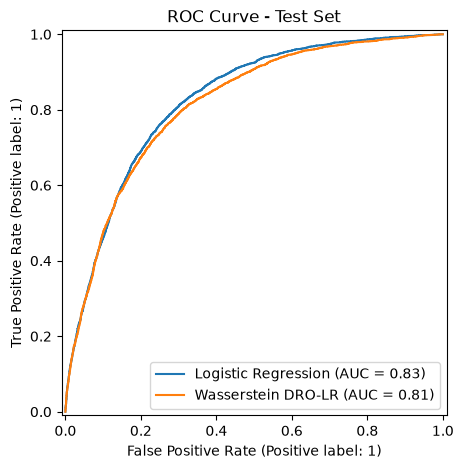

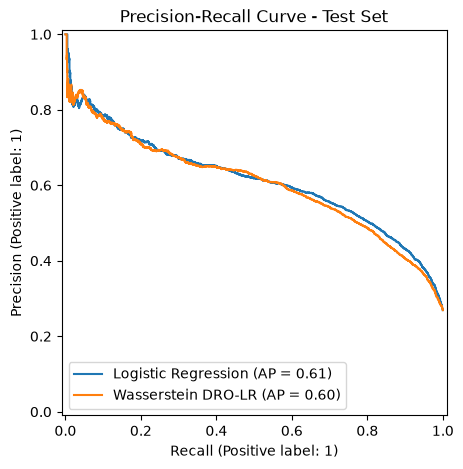

In [119]:
# FINAL EVALUATION PLOTS

import matplotlib.pyplot as plt
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

y_true = y_test_tensor.numpy().ravel().astype(int)

# 1. ROC Curves
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_true, lr_probabilities,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_true, dro_probabilities,
    name="Wasserstein DRO-LR",
    ax=ax
)

ax.set_title("ROC Curve - Test Set")
plt.show()


# 2. Precision-Recall Curves
fig, ax = plt.subplots(figsize=(7, 5))

PrecisionRecallDisplay.from_predictions(
    y_true, lr_probabilities,
    name="Logistic Regression",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_true, dro_probabilities,
    name="Wasserstein DRO-LR",
    ax=ax
)

ax.set_title("Precision-Recall Curve - Test Set")
plt.show()